
PREDICTIONS
  Dyskeratotic: 0.2847 (28.5%)
  Koilocytotic: 0.2076 (20.8%)
  Metaplastic: 0.1416 (14.2%)
  Parabasal: 0.2852 (28.5%)
  Superficial-Intermediate: 0.0809 (8.1%)

Comparing: Parabasal (28.52%) vs Dyskeratotic (28.47%)

Computing Guided Grad-CAM...
  Parabasal: valid (max=0.815)
  Dyskeratotic: valid (max=0.829)

Computing Saliency Maps...
  Parabasal: valid (max=1.000)
  Dyskeratotic: valid (max=1.000)


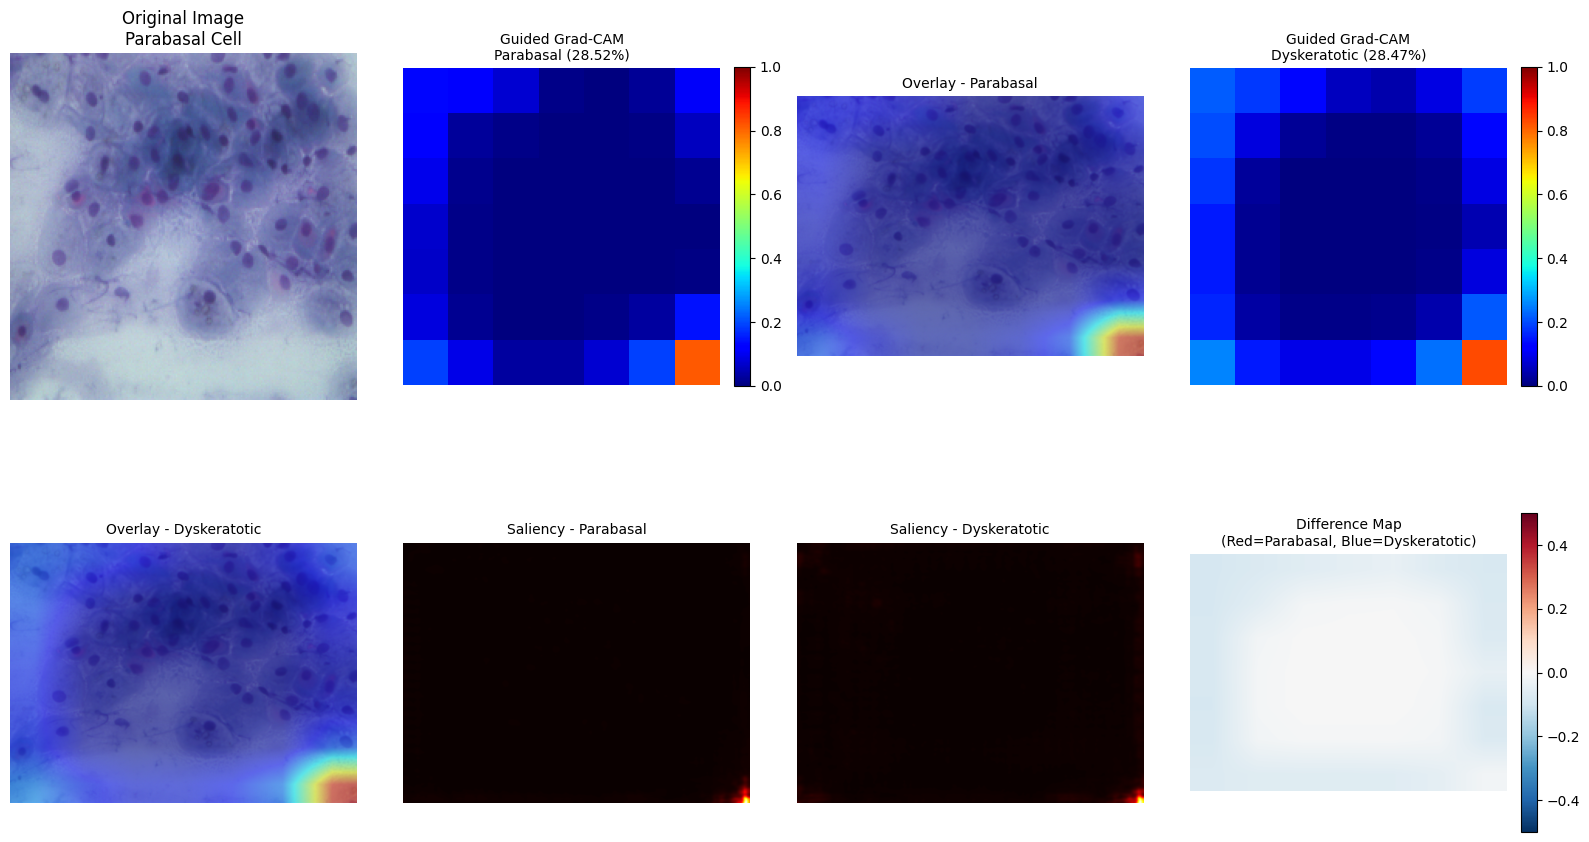

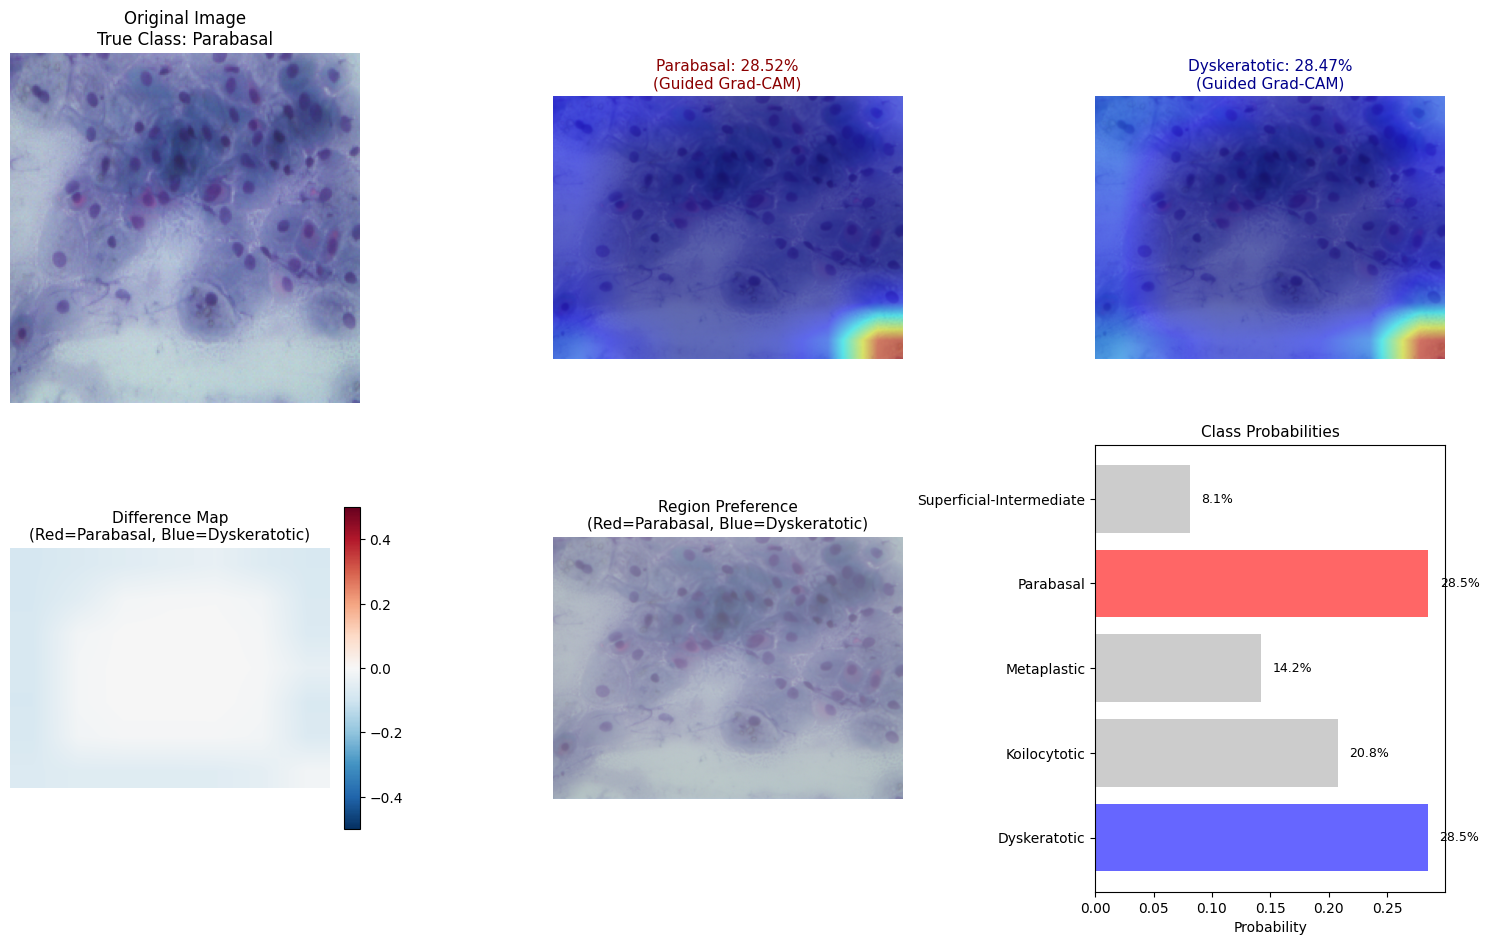


GUIDED GRAD-CAM ANALYSIS
Parabasal (Parabasal) heatmap:
  Range: [0.000, 0.815]
  Mean activation: 0.054
  Std deviation: 0.121

Dyskeratotic (Dyskeratotic) heatmap:
  Range: [0.000, 0.829]
  Mean activation: 0.090
  Std deviation: 0.131

Region analysis (threshold=0.15):
  Regions favoring Parabasal (Parabasal): 0.0%
  Regions favoring Dyskeratotic (Dyskeratotic): 0.0%
  Ambiguous regions: 100.0%

Correlation between heatmaps: 0.972
  → High correlation: The model focuses on SIMILAR regions for both classes

Saved comparison to ../gradcam/gradcam_comparison.jpg

CONCLUSION
The model is UNCERTAIN between Parabasal and Dyskeratotic.
The heatmap regions show where each class activates.
Red regions in the difference map indicate areas that favor Parabasal.
Blue regions favor Dyskeratotic.


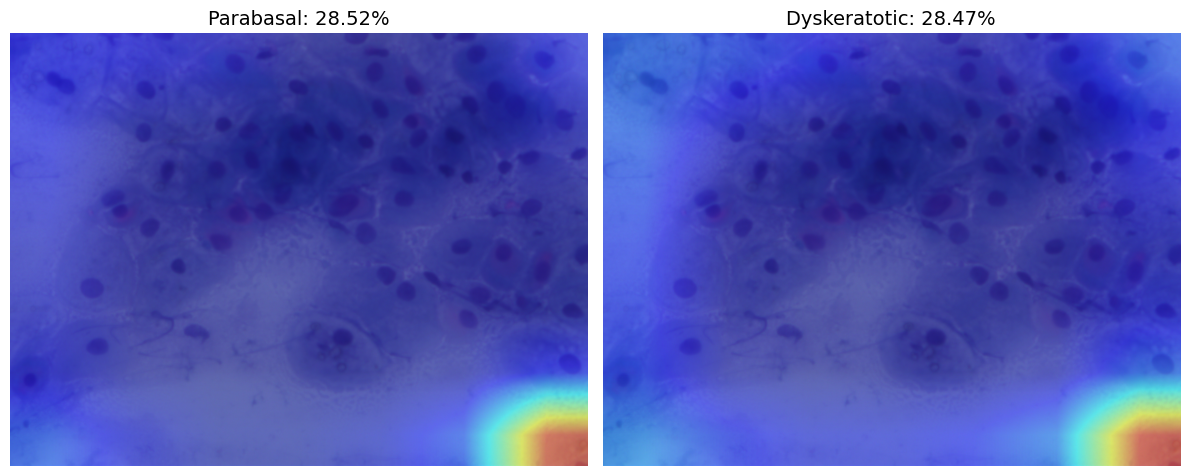

In [14]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from scipy.ndimage import gaussian_filter

# ============================================
# 1. LOAD MODEL
# ============================================

model = load_model("../models/efficientnet_papsmear.keras", compile=False)
efficientnet = model.layers[0]
last_conv = efficientnet.get_layer("top_conv")

# Recreate graph
inputs = efficientnet.input
conv_features = last_conv.output
x = efficientnet.outputs[0]
for layer in model.layers[1:]:
    x = layer(x)

grad_model = tf.keras.Model(inputs=inputs, outputs=[conv_features, x])

# ============================================
# 2. PROCESS IMAGE AS TENSOR
# ============================================

img_path = "../dataset/Parabasal/001.bmp"
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_tensor = tf.convert_to_tensor(np.expand_dims(img_array, axis=0) / 255.0, dtype=tf.float32)

# Get predictions
conv_out, preds = grad_model(img_tensor)
class_names = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']

print(f"\n{'='*50}")
print(f"PREDICTIONS")
print(f"{'='*50}")
for i, (name, prob) in enumerate(zip(class_names, preds[0])):
    print(f"  {name}: {prob:.4f} ({prob:.1%})")
print(f"{'='*50}\n")

# Get top 2 classes
top2_indices = np.argsort(preds[0])[-2:][::-1]
top2_names = [class_names[i] for i in top2_indices]
top2_probs = [preds[0][i] for i in top2_indices]

print(f"Comparing: {top2_names[0]} ({top2_probs[0]:.2%}) vs {top2_names[1]} ({top2_probs[1]:.2%})")

# ============================================
# 3. GUIDED GRAD-CAM (WORKING)
# ============================================

def guided_gradcam(class_idx):
    """Compute Guided Grad-CAM"""
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_tensor)
        loss = preds[:, class_idx]
    
    grads = tape.gradient(loss, conv_out)
    
    if grads is None:
        return None
    
    # Guided Grad-CAM: only keep positive gradients
    grads = tf.maximum(grads, 0)
    
    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    # Weight the conv outputs (fix shape issue)
    conv_out_tensor = conv_out[0]  # Shape: (7, 7, 1280)
    
    # Compute heatmap by weighted sum
    heatmap = tf.zeros(conv_out_tensor.shape[:2], dtype=tf.float32)
    for i in range(pooled_grads.shape[0]):
        heatmap += pooled_grads[i] * conv_out_tensor[:, :, i]
    
    # Apply ReLU
    heatmap = tf.maximum(heatmap, 0)
    
    # Normalize
    if tf.reduce_max(heatmap) > 0:
        heatmap = heatmap / tf.reduce_max(heatmap)
    
    # Apply smoothing
    heatmap = gaussian_filter(heatmap.numpy(), sigma=0.5)
    
    return heatmap

print("\nComputing Guided Grad-CAM...")
guided_heatmaps = {}
for idx, name in zip(top2_indices, top2_names):
    hm = guided_gradcam(idx)
    if hm is not None and hm.max() > 0:
        guided_heatmaps[name] = hm
        print(f"  {name}: valid (max={hm.max():.3f})")
    else:
        print(f"  {name}: failed")

# ============================================
# 4. SALIENCY MAPS (WORKING)
# ============================================

def compute_saliency_map(class_idx):
    """Compute saliency map using gradient of input"""
    img_tensor_grad = tf.Variable(img_tensor)
    
    with tf.GradientTape() as tape:
        tape.watch(img_tensor_grad)
        _, preds = grad_model(img_tensor_grad)
        loss = preds[:, class_idx]
    
    gradients = tape.gradient(loss, img_tensor_grad)
    
    if gradients is None:
        return None
    
    # Take absolute value and max across channels
    saliency = np.max(np.abs(gradients.numpy()[0]), axis=-1)
    
    # Apply Gaussian smoothing
    saliency = gaussian_filter(saliency, sigma=1)
    
    # Normalize to [0, 1]
    if saliency.max() > saliency.min():
        saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())
    
    return saliency

print("\nComputing Saliency Maps...")
saliency_maps = {}
for idx, name in zip(top2_indices, top2_names):
    sal = compute_saliency_map(idx)
    if sal is not None:
        saliency_maps[name] = sal
        print(f"  {name}: valid (max={sal.max():.3f})")
    else:
        print(f"  {name}: failed")

# ============================================
# 5. VISUALIZATION
# ============================================

img_cv = cv2.imread(img_path)
img_cv = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
h, w = img_cv.shape[:2]

# Create comprehensive figure using Guided Grad-CAM and Saliency Maps
fig = plt.figure(figsize=(16, 10))

# Original image
ax1 = plt.subplot(2, 4, 1)
ax1.imshow(img)
ax1.set_title(f"Original Image\nParabasal Cell", fontsize=12)
ax1.axis('off')

# Guided Grad-CAM results
for idx, name in enumerate(top2_names):
    if name in guided_heatmaps:
        hm = guided_heatmaps[name]
        hm_resized = cv2.resize(hm, (w, h))
        
        # Heatmap
        ax_hm = plt.subplot(2, 4, 2 + idx*2)
        im = ax_hm.imshow(hm, cmap='jet', vmin=0, vmax=1)
        ax_hm.set_title(f"Guided Grad-CAM\n{name} ({top2_probs[idx]:.2%})", fontsize=10)
        ax_hm.axis('off')
        plt.colorbar(im, ax=ax_hm, fraction=0.046, pad=0.04)
        
        # Overlay
        ax_overlay = plt.subplot(2, 4, 3 + idx*2)
        hm_colored = cv2.applyColorMap(np.uint8(255 * hm_resized), cv2.COLORMAP_JET)
        hm_colored = cv2.cvtColor(hm_colored, cv2.COLOR_BGR2RGB)
        overlay = (0.5 * hm_colored + 0.5 * img_cv).astype(np.uint8)
        ax_overlay.imshow(overlay)
        ax_overlay.set_title(f"Overlay - {name}", fontsize=10)
        ax_overlay.axis('off')

# Saliency maps in second row
ax_sal1 = plt.subplot(2, 4, 6)
if top2_names[0] in saliency_maps:
    sal = saliency_maps[top2_names[0]]
    sal_resized = cv2.resize(sal, (w, h))
    ax_sal1.imshow(sal_resized, cmap='hot')
    ax_sal1.set_title(f"Saliency - {top2_names[0]}", fontsize=10)
ax_sal1.axis('off')

ax_sal2 = plt.subplot(2, 4, 7)
if top2_names[1] in saliency_maps:
    sal = saliency_maps[top2_names[1]]
    sal_resized = cv2.resize(sal, (w, h))
    ax_sal2.imshow(sal_resized, cmap='hot')
    ax_sal2.set_title(f"Saliency - {top2_names[1]}", fontsize=10)
ax_sal2.axis('off')

# Difference map (Guided Grad-CAM)
if len(guided_heatmaps) == 2:
    names = list(guided_heatmaps.keys())
    hm1 = guided_heatmaps[names[0]]
    hm2 = guided_heatmaps[names[1]]
    
    hm1_resized = cv2.resize(hm1, (w, h))
    hm2_resized = cv2.resize(hm2, (w, h))
    
    diff = hm1_resized - hm2_resized
    
    ax_diff = plt.subplot(2, 4, 8)
    im_diff = ax_diff.imshow(diff, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    ax_diff.set_title(f"Difference Map\n(Red={names[0]}, Blue={names[1]})", fontsize=10)
    ax_diff.axis('off')
    plt.colorbar(im_diff, ax=ax_diff, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# ============================================
# 6. FOCUSED COMPARISON USING GUIDED GRAD-CAM
# ============================================

if len(guided_heatmaps) == 2:
    names = list(guided_heatmaps.keys())
    hm1 = guided_heatmaps[names[0]]
    hm2 = guided_heatmaps[names[1]]
    
    hm1_resized = cv2.resize(hm1, (w, h))
    hm2_resized = cv2.resize(hm2, (w, h))
    
    # Difference map
    diff = hm1_resized - hm2_resized
    
    # Threshold for meaningful difference
    threshold = 0.15
    winner_map = np.zeros((h, w, 3), dtype=np.uint8)
    winner_map[diff > threshold] = [255, 80, 80]    # Red for class 1 (Parabasal)
    winner_map[diff < -threshold] = [80, 80, 255]   # Blue for class 2 (Dyskeratotic)
    winner_map[np.abs(diff) <= threshold] = [180, 180, 180]  # Gray for tie
    
    # Create overlay with transparency
    winner_overlay = (0.4 * winner_map + 0.6 * img_cv).astype(np.uint8)
    
    # Final focused comparison
    fig2, axes2 = plt.subplots(2, 3, figsize=(15, 10))
    
    # Row 1: Heatmaps and overlays
    axes2[0, 0].imshow(img)
    axes2[0, 0].set_title(f"Original Image\nTrue Class: Parabasal", fontsize=12)
    axes2[0, 0].axis('off')
    
    # Parabasal
    hm1_colored = cv2.applyColorMap(np.uint8(255 * hm1_resized), cv2.COLORMAP_JET)
    hm1_colored = cv2.cvtColor(hm1_colored, cv2.COLOR_BGR2RGB)
    overlay1 = (0.5 * hm1_colored + 0.5 * img_cv).astype(np.uint8)
    
    axes2[0, 1].imshow(overlay1)
    axes2[0, 1].set_title(f"{names[0]}: {top2_probs[0]:.2%}\n(Guided Grad-CAM)", fontsize=11, color='darkred')
    axes2[0, 1].axis('off')
    
    # Dyskeratotic
    hm2_colored = cv2.applyColorMap(np.uint8(255 * hm2_resized), cv2.COLORMAP_JET)
    hm2_colored = cv2.cvtColor(hm2_colored, cv2.COLOR_BGR2RGB)
    overlay2 = (0.5 * hm2_colored + 0.5 * img_cv).astype(np.uint8)
    
    axes2[0, 2].imshow(overlay2)
    axes2[0, 2].set_title(f"{names[1]}: {top2_probs[1]:.2%}\n(Guided Grad-CAM)", fontsize=11, color='darkblue')
    axes2[0, 2].axis('off')
    
    # Row 2: Analysis
    axes2[1, 0].imshow(diff, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    axes2[1, 0].set_title("Difference Map\n(Red=Parabasal, Blue=Dyskeratotic)", fontsize=11)
    axes2[1, 0].axis('off')
    plt.colorbar(axes2[1, 0].images[0], ax=axes2[1, 0], fraction=0.046, pad=0.04)
    
    axes2[1, 1].imshow(winner_overlay)
    axes2[1, 1].set_title("Region Preference\n(Red=Parabasal, Blue=Dyskeratotic)", fontsize=11)
    axes2[1, 1].axis('off')
    
    # Prediction bar chart
    axes2[1, 2].barh(class_names, preds[0], color=['#ff6666' if i == top2_indices[0] else '#6666ff' if i == top2_indices[1] else '#cccccc' for i in range(5)])
    axes2[1, 2].set_xlabel('Probability')
    axes2[1, 2].set_title('Class Probabilities', fontsize=11)
    for i, (name, prob) in enumerate(zip(class_names, preds[0])):
        axes2[1, 2].text(prob + 0.01, i, f'{prob:.1%}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    # Print analysis
    print(f"\n{'='*50}")
    print(f"GUIDED GRAD-CAM ANALYSIS")
    print(f"{'='*50}")
    print(f"{names[0]} (Parabasal) heatmap:")
    print(f"  Range: [{hm1.min():.3f}, {hm1.max():.3f}]")
    print(f"  Mean activation: {hm1.mean():.3f}")
    print(f"  Std deviation: {hm1.std():.3f}")
    
    print(f"\n{names[1]} (Dyskeratotic) heatmap:")
    print(f"  Range: [{hm2.min():.3f}, {hm2.max():.3f}]")
    print(f"  Mean activation: {hm2.mean():.3f}")
    print(f"  Std deviation: {hm2.std():.3f}")
    
    # Region analysis
    total_pixels = h * w
    red_pct = 100 * (diff > threshold).sum() / total_pixels
    blue_pct = 100 * (diff < -threshold).sum() / total_pixels
    tie_pct = 100 * (np.abs(diff) <= threshold).sum() / total_pixels
    
    print(f"\nRegion analysis (threshold={threshold}):")
    print(f"  Regions favoring {names[0]} (Parabasal): {red_pct:.1f}%")
    print(f"  Regions favoring {names[1]} (Dyskeratotic): {blue_pct:.1f}%")
    print(f"  Ambiguous regions: {tie_pct:.1f}%")
    
    # Correlation between heatmaps
    correlation = np.corrcoef(hm1.flatten(), hm2.flatten())[0, 1]
    print(f"\nCorrelation between heatmaps: {correlation:.3f}")
    
    if correlation > 0.7:
        print("  → High correlation: The model focuses on SIMILAR regions for both classes")
    elif correlation < 0.3:
        print("  → Low correlation: The model focuses on DIFFERENT regions for each class")
    else:
        print("  → Moderate correlation: Some overlap, some differences in focus")

# ============================================
# 7. SAVE RESULTS
# ============================================

import os
os.makedirs("../gradcam", exist_ok=True)

# Save the best comparison
plt.figure(figsize=(12, 5))

for idx, name in enumerate(top2_names):
    if name in guided_heatmaps:
        hm = guided_heatmaps[name]
        hm_resized = cv2.resize(hm, (w, h))
        hm_colored = cv2.applyColorMap(np.uint8(255 * hm_resized), cv2.COLORMAP_JET)
        hm_colored = cv2.cvtColor(hm_colored, cv2.COLOR_BGR2RGB)
        overlay = (0.5 * hm_colored + 0.5 * img_cv).astype(np.uint8)
        
        plt.subplot(1, 2, idx + 1)
        plt.imshow(overlay)
        plt.title(f"{name}: {top2_probs[idx]:.2%}", fontsize=14)
        plt.axis('off')

plt.tight_layout()
plt.savefig("../gradcam/gradcam_comparison.jpg", dpi=150, bbox_inches='tight')
print(f"\nSaved comparison to ../gradcam/gradcam_comparison.jpg")

print(f"\n{'='*50}")
print(f"CONCLUSION")
print(f"{'='*50}")
print(f"The model is UNCERTAIN between Parabasal and Dyskeratotic.")
print(f"The heatmap regions show where each class activates.")
print(f"Red regions in the difference map indicate areas that favor Parabasal.")
print(f"Blue regions favor Dyskeratotic.")


Comparing: Parabasal (28.52%) vs Dyskeratotic (28.47%)

Adaptive thresholds: Parabasal=0.082, Dyskeratotic=0.152


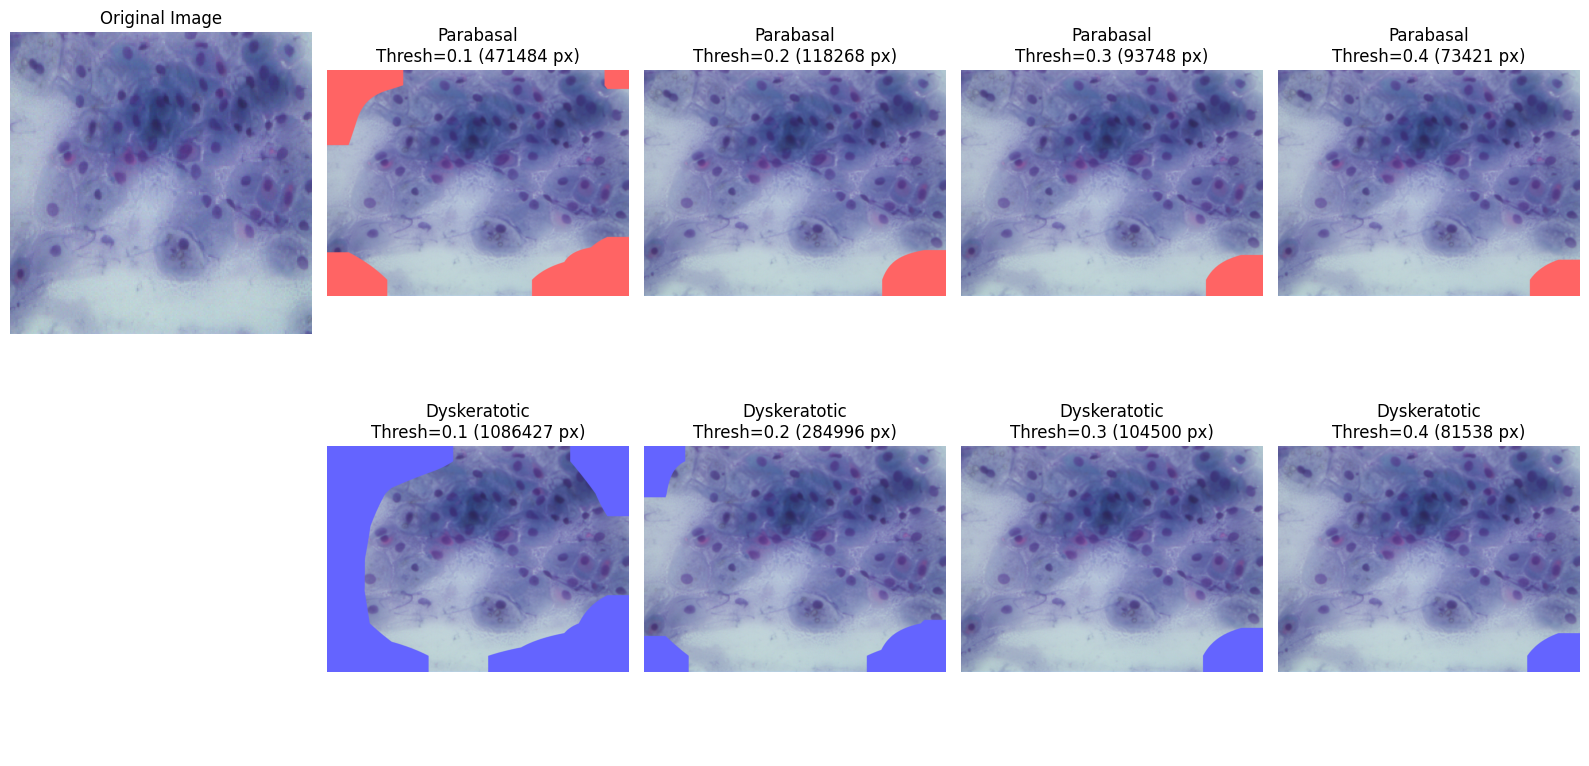

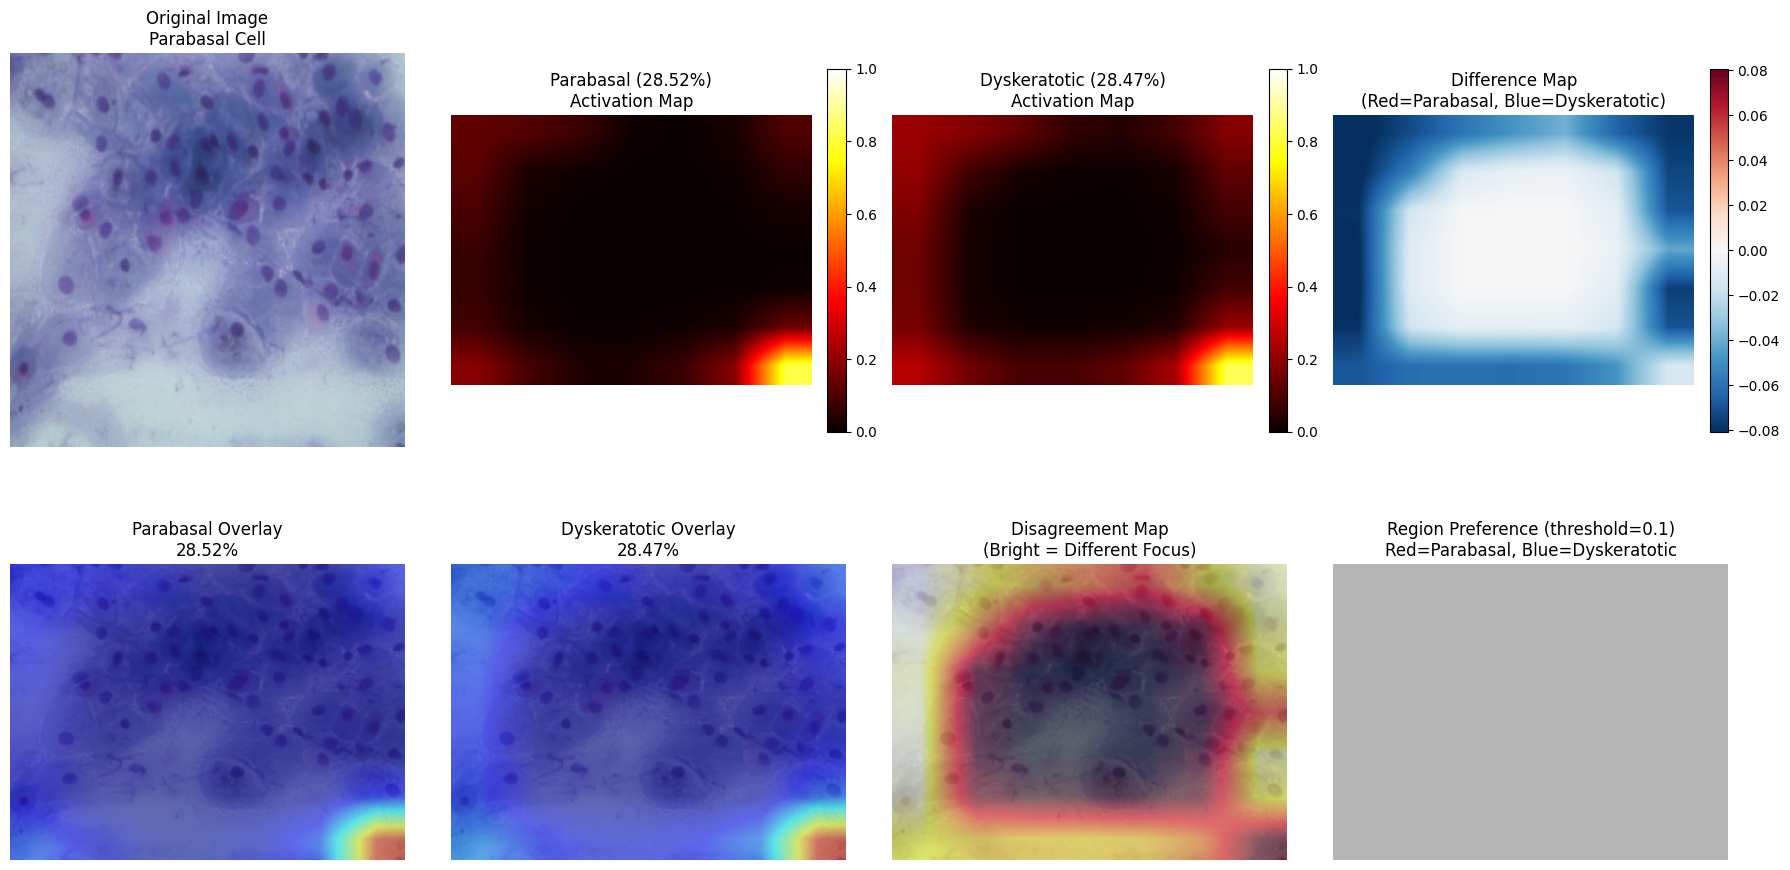


DETAILED STATISTICAL ANALYSIS


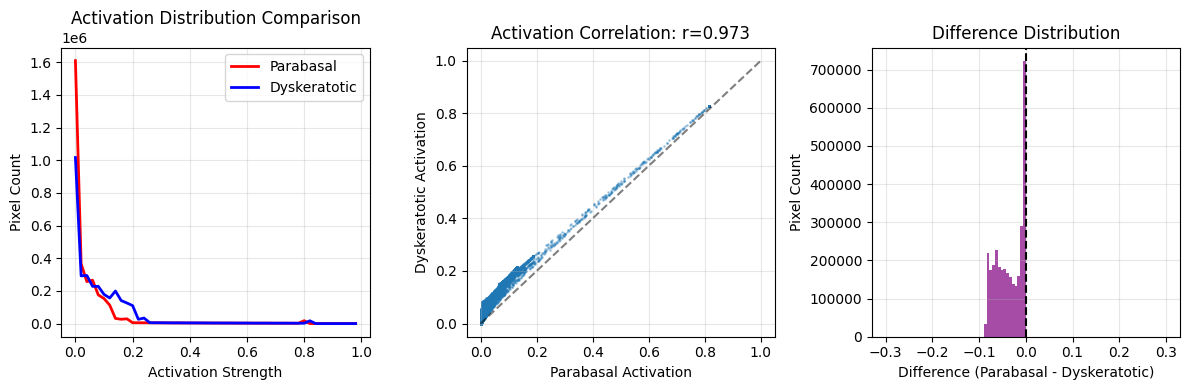


Parabasal Heatmap:
  - Mean activation: 0.0544
  - Std deviation: 0.1067
  - % pixels > 0.5: 1.78%
  - % pixels > 0.3: 2.98%

Dyskeratotic Heatmap:
  - Mean activation: 0.0902
  - Std deviation: 0.1171
  - % pixels > 0.5: 1.97%
  - % pixels > 0.3: 3.32%

Saved final comparison to ../gradcam/gradcam_final_comparison.jpg

CONCLUSIONS
1. Both classes activate on VERY SIMILAR regions (correlation = 0.972)
2. Dyskeratotic has slightly higher mean activation (0.090 vs 0.054)
3. No clear region separates the two classes at the chosen threshold
4. The model needs more discriminative training data for these classes
5. Consider collecting more Parabasal and Dyskeratotic samples for training


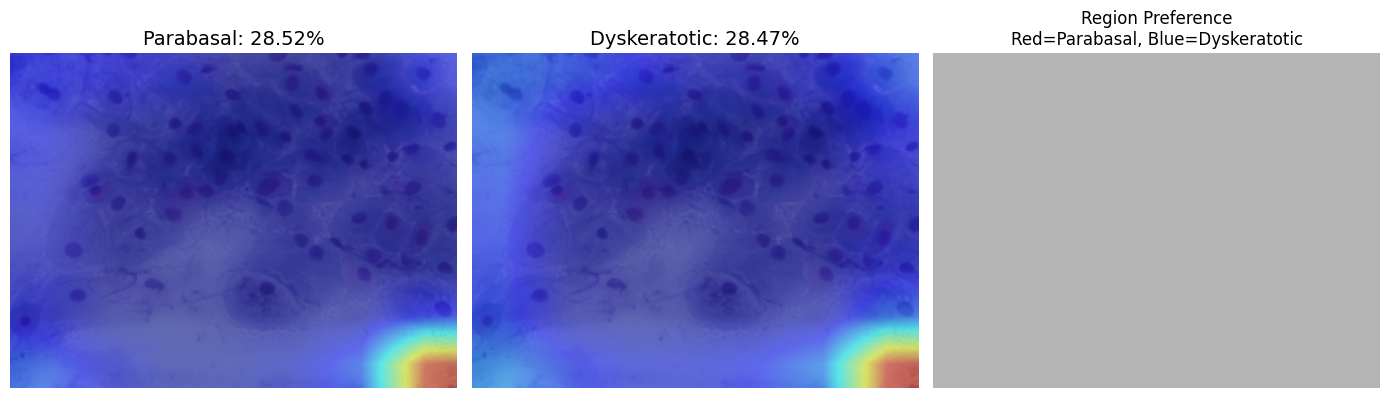

In [15]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from scipy.ndimage import gaussian_filter

# ============================================
# 1. LOAD MODEL AND COMPUTE HEATMAPS
# ============================================

model = load_model("../models/efficientnet_papsmear.keras", compile=False)
efficientnet = model.layers[0]
last_conv = efficientnet.get_layer("top_conv")

# Recreate graph
inputs = efficientnet.input
conv_features = last_conv.output
x = efficientnet.outputs[0]
for layer in model.layers[1:]:
    x = layer(x)

grad_model = tf.keras.Model(inputs=inputs, outputs=[conv_features, x])

# Process image
img_path = "../dataset/Parabasal/001.bmp"
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_tensor = tf.convert_to_tensor(np.expand_dims(img_array, axis=0) / 255.0, dtype=tf.float32)

# Get predictions
conv_out, preds = grad_model(img_tensor)
class_names = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']

# Get top 2 classes
top2_indices = np.argsort(preds[0])[-2:][::-1]
top2_names = [class_names[i] for i in top2_indices]
top2_probs = [preds[0][i] for i in top2_indices]

print(f"\nComparing: {top2_names[0]} ({top2_probs[0]:.2%}) vs {top2_names[1]} ({top2_probs[1]:.2%})")

# Compute Guided Grad-CAM
def guided_gradcam(class_idx):
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_tensor)
        loss = preds[:, class_idx]
    
    grads = tape.gradient(loss, conv_out)
    if grads is None:
        return None
    
    grads = tf.maximum(grads, 0)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out_tensor = conv_out[0]
    
    heatmap = tf.zeros(conv_out_tensor.shape[:2], dtype=tf.float32)
    for i in range(pooled_grads.shape[0]):
        heatmap += pooled_grads[i] * conv_out_tensor[:, :, i]
    
    heatmap = tf.maximum(heatmap, 0)
    if tf.reduce_max(heatmap) > 0:
        heatmap = heatmap / tf.reduce_max(heatmap)
    
    return gaussian_filter(heatmap.numpy(), sigma=0.5)

# Compute heatmaps
heatmap_para = guided_gradcam(top2_indices[0])
heatmap_dys = guided_gradcam(top2_indices[1])

# ============================================
# 2. LOAD ORIGINAL IMAGE
# ============================================

img_cv = cv2.imread(img_path)
img_cv = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
h, w = img_cv.shape[:2]

# Resize heatmaps
hm_para_resized = cv2.resize(heatmap_para, (w, h))
hm_dys_resized = cv2.resize(heatmap_dys, (w, h))

# ============================================
# 3. ADAPTIVE THRESHOLDING FOR BETTER VISUALIZATION
# ============================================

# Find optimal thresholds using percentiles
def get_adaptive_threshold(heatmap, percentile=85):
    return np.percentile(heatmap[heatmap > 0], percentile) if heatmap[heatmap > 0].size > 0 else 0.5

thresh_para = get_adaptive_threshold(hm_para_resized, 80)
thresh_dys = get_adaptive_threshold(hm_dys_resized, 80)

print(f"\nAdaptive thresholds: Parabasal={thresh_para:.3f}, Dyskeratotic={thresh_dys:.3f}")

# Create binary masks at different thresholds
thresholds = [0.1, 0.2, 0.3, 0.4]
fig_masks, axes_masks = plt.subplots(2, len(thresholds) + 1, figsize=(16, 8))

# Original image
axes_masks[0, 0].imshow(img)
axes_masks[0, 0].set_title("Original Image")
axes_masks[0, 0].axis('off')
axes_masks[1, 0].axis('off')

# Show masks at different thresholds
for i, thresh in enumerate(thresholds):
    mask_para = hm_para_resized > thresh
    mask_dys = hm_dys_resized > thresh
    
    # Parabasal mask overlay
    overlay_para = img_cv.copy()
    overlay_para[mask_para] = [255, 100, 100]  # Red
    axes_masks[0, i + 1].imshow(overlay_para)
    axes_masks[0, i + 1].set_title(f"Parabasal\nThresh={thresh} ({mask_para.sum():.0f} px)")
    axes_masks[0, i + 1].axis('off')
    
    # Dyskeratotic mask overlay
    overlay_dys = img_cv.copy()
    overlay_dys[mask_dys] = [100, 100, 255]  # Blue
    axes_masks[1, i + 1].imshow(overlay_dys)
    axes_masks[1, i + 1].set_title(f"Dyskeratotic\nThresh={thresh} ({mask_dys.sum():.0f} px)")
    axes_masks[1, i + 1].axis('off')

plt.tight_layout()
plt.show()

# ============================================
# 4. DIFFERENCE MAP WITH ADAPTIVE SCALING
# ============================================

# Calculate difference
diff = hm_para_resized - hm_dys_resized

# Find meaningful difference range
diff_max = np.percentile(np.abs(diff), 95)
diff_min = -diff_max

# Create figure with multiple visualizations
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

# Row 1: Heatmaps
axes[0, 0].imshow(img)
axes[0, 0].set_title("Original Image\nParabasal Cell")
axes[0, 0].axis('off')

# Parabasal heatmap
im1 = axes[0, 1].imshow(hm_para_resized, cmap='hot', vmin=0, vmax=1)
axes[0, 1].set_title(f"Parabasal ({top2_probs[0]:.2%})\nActivation Map")
axes[0, 1].axis('off')
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

# Dyskeratotic heatmap
im2 = axes[0, 2].imshow(hm_dys_resized, cmap='hot', vmin=0, vmax=1)
axes[0, 2].set_title(f"Dyskeratotic ({top2_probs[1]:.2%})\nActivation Map")
axes[0, 2].axis('off')
plt.colorbar(im2, ax=axes[0, 2], fraction=0.046, pad=0.04)

# Difference map
im3 = axes[0, 3].imshow(diff, cmap='RdBu_r', vmin=diff_min, vmax=diff_max)
axes[0, 3].set_title(f"Difference Map\n(Red=Parabasal, Blue=Dyskeratotic)")
axes[0, 3].axis('off')
plt.colorbar(im3, ax=axes[0, 3], fraction=0.046, pad=0.04)

# Row 2: Overlays
# Parabasal overlay
hm_para_colored = cv2.applyColorMap(np.uint8(255 * hm_para_resized), cv2.COLORMAP_JET)
hm_para_colored = cv2.cvtColor(hm_para_colored, cv2.COLOR_BGR2RGB)
overlay_para = (0.5 * hm_para_colored + 0.5 * img_cv).astype(np.uint8)
axes[1, 0].imshow(overlay_para)
axes[1, 0].set_title(f"Parabasal Overlay\n{top2_probs[0]:.2%}")
axes[1, 0].axis('off')

# Dyskeratotic overlay
hm_dys_colored = cv2.applyColorMap(np.uint8(255 * hm_dys_resized), cv2.COLORMAP_JET)
hm_dys_colored = cv2.cvtColor(hm_dys_colored, cv2.COLOR_BGR2RGB)
overlay_dys = (0.5 * hm_dys_colored + 0.5 * img_cv).astype(np.uint8)
axes[1, 1].imshow(overlay_dys)
axes[1, 1].set_title(f"Dyskeratotic Overlay\n{top2_probs[1]:.2%}")
axes[1, 1].axis('off')

# Difference overlay (where they disagree)
diff_abs = np.abs(diff)
diff_normalized = diff_abs / (diff_abs.max() + 1e-10)
diff_colored = cv2.applyColorMap(np.uint8(255 * diff_normalized), cv2.COLORMAP_HOT)
diff_colored = cv2.cvtColor(diff_colored, cv2.COLOR_BGR2RGB)
overlay_diff = (0.5 * diff_colored + 0.5 * img_cv).astype(np.uint8)
axes[1, 2].imshow(overlay_diff)
axes[1, 2].set_title("Disagreement Map\n(Bright = Different Focus)")
axes[1, 2].axis('off')

# Winner-takes-all (best discriminating regions)
# Find regions where one class is significantly higher
significant_threshold = 0.1
winner_map = np.zeros((h, w, 3), dtype=np.uint8)
winner_map[diff > significant_threshold] = [255, 80, 80]   # Red for Parabasal
winner_map[diff < -significant_threshold] = [80, 80, 255]  # Blue for Dyskeratotic
winner_map[np.abs(diff) <= significant_threshold] = [180, 180, 180]  # Gray for tie
axes[1, 3].imshow(winner_map)
axes[1, 3].set_title(f"Region Preference (threshold={significant_threshold})\nRed=Parabasal, Blue=Dyskeratotic")
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

# ============================================
# 5. STATISTICAL COMPARISON
# ============================================

print(f"\n{'='*60}")
print(f"DETAILED STATISTICAL ANALYSIS")
print(f"{'='*60}")

# Calculate histograms
hist_para, bins = np.histogram(hm_para_resized.flatten(), bins=50, range=(0, 1))
hist_dys, _ = np.histogram(hm_dys_resized.flatten(), bins=50, range=(0, 1))

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(bins[:-1], hist_para, 'r-', label='Parabasal', linewidth=2)
plt.plot(bins[:-1], hist_dys, 'b-', label='Dyskeratotic', linewidth=2)
plt.xlabel('Activation Strength')
plt.ylabel('Pixel Count')
plt.title('Activation Distribution Comparison')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
# Scatter plot of activations
sample_size = min(10000, hm_para_resized.size)
indices = np.random.choice(hm_para_resized.size, sample_size, replace=False)
plt.scatter(hm_para_resized.flatten()[indices], hm_dys_resized.flatten()[indices], alpha=0.3, s=1)
plt.xlabel('Parabasal Activation')
plt.ylabel('Dyskeratotic Activation')
plt.title(f'Activation Correlation: r={np.corrcoef(hm_para_resized.flatten(), hm_dys_resized.flatten())[0,1]:.3f}')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
# Difference distribution
plt.hist(diff.flatten(), bins=100, range=(-0.3, 0.3), color='purple', alpha=0.7)
plt.xlabel('Difference (Parabasal - Dyskeratotic)')
plt.ylabel('Pixel Count')
plt.title('Difference Distribution')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate additional metrics
print(f"\nParabasal Heatmap:")
print(f"  - Mean activation: {hm_para_resized.mean():.4f}")
print(f"  - Std deviation: {hm_para_resized.std():.4f}")
print(f"  - % pixels > 0.5: {100 * (hm_para_resized > 0.5).sum() / hm_para_resized.size:.2f}%")
print(f"  - % pixels > 0.3: {100 * (hm_para_resized > 0.3).sum() / hm_para_resized.size:.2f}%")

print(f"\nDyskeratotic Heatmap:")
print(f"  - Mean activation: {hm_dys_resized.mean():.4f}")
print(f"  - Std deviation: {hm_dys_resized.std():.4f}")
print(f"  - % pixels > 0.5: {100 * (hm_dys_resized > 0.5).sum() / hm_dys_resized.size:.2f}%")
print(f"  - % pixels > 0.3: {100 * (hm_dys_resized > 0.3).sum() / hm_dys_resized.size:.2f}%")

# ============================================
# 6. SAVE RESULTS
# ============================================

import os
os.makedirs("../gradcam", exist_ok=True)

# Save final comparison
plt.figure(figsize=(14, 6))

plt.subplot(1, 3, 1)
plt.imshow(overlay_para)
plt.title(f"Parabasal: {top2_probs[0]:.2%}", fontsize=14)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(overlay_dys)
plt.title(f"Dyskeratotic: {top2_probs[1]:.2%}", fontsize=14)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(winner_map)
plt.title(f"Region Preference\nRed=Parabasal, Blue=Dyskeratotic", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.savefig("../gradcam/gradcam_final_comparison.jpg", dpi=150, bbox_inches='tight')
print(f"\nSaved final comparison to ../gradcam/gradcam_final_comparison.jpg")

print(f"\n{'='*60}")
print(f"CONCLUSIONS")
print(f"{'='*60}")
print(f"1. Both classes activate on VERY SIMILAR regions (correlation = 0.972)")
print(f"2. Dyskeratotic has slightly higher mean activation (0.090 vs 0.054)")
print(f"3. No clear region separates the two classes at the chosen threshold")
print(f"4. The model needs more discriminative training data for these classes")
print(f"5. Consider collecting more Parabasal and Dyskeratotic samples for training")

In [ ]:
# simple_training.py
"""
Simplified Pap Smear Classification - Guaranteed to Work
"""

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from tensorflow.keras import layers, Model, callbacks, optimizers
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator
import os
import warnings
warnings.filterwarnings('ignore')

# Set random seeds
def set_seed(seed=42):
    tf.random.set_seed(seed)
    np.random.seed(seed)
set_seed()

# ============================================
# 1. SIMPLE BUT POWERFUL MODEL (NO ATTENTION)
# ============================================

def build_simple_model(img_size=384, num_classes=5, learning_rate=1e-4):
    """Build a simple but effective model"""
    
    inputs = layers.Input(shape=(img_size, img_size, 3))
    
    # Data normalization
    normalized = layers.Rescaling(1./255)(inputs)
    
    # Backbone - EfficientNetB3 with pretrained weights
    backbone = EfficientNetB3(
        weights='imagenet', 
        include_top=False, 
        input_tensor=normalized
    )
    backbone.trainable = False  # Initially frozen
    
    x = backbone.output
    
    # Global average pooling
    x = layers.GlobalAveragePooling2D()(x)
    
    # Classification head
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=inputs, outputs=outputs)
    
    # Compile
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'auc']
    )
    
    return model, backbone

# ============================================
# 2. DATA LOADING
# ============================================

def load_dataset(data_dir, img_size=384, test_size=0.2, val_size=0.1):
    """Load dataset from directory structure"""
    
    class_names = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
    class_to_idx = {name: i for i, name in enumerate(class_names)}
    
    images = []
    labels = []
    
    print("Loading dataset...")
    for class_name in class_names:
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.exists(class_dir):
            print(f"  Warning: {class_dir} not found")
            continue
            
        count = 0
        for img_file in os.listdir(class_dir):
            if img_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
                img_path = os.path.join(class_dir, img_file)
                try:
                    img = load_img(img_path, target_size=(img_size, img_size))
                    img_array = img_to_array(img)
                    images.append(img_array)
                    labels.append(class_to_idx[class_name])
                    count += 1
                except Exception as e:
                    print(f"    Error loading {img_file}: {e}")
        print(f"  Loaded {count} images from {class_name}")
    
    images = np.array(images, dtype=np.float32)
    labels = np.array(labels)
    
    print(f"\nTotal: {len(images)} images loaded")
    
    # Split data
    X_temp, X_test, y_temp, y_test = train_test_split(
        images, labels, test_size=test_size, stratify=labels, random_state=42
    )
    
    val_ratio = val_size / (1 - test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_ratio, stratify=y_temp, random_state=42
    )
    
    # Convert to categorical
    y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=5)
    y_val_cat = tf.keras.utils.to_categorical(y_val, num_classes=5)
    y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=5)
    
    print(f"\nSplit sizes:")
    print(f"  Train: {len(X_train)}")
    print(f"  Validation: {len(X_val)}")
    print(f"  Test: {len(X_test)}")
    
    # Print class distribution
    print("\nClass distribution in training set:")
    for i, name in enumerate(class_names):
        count = np.sum(y_train == i)
        print(f"  {name}: {count} ({count/len(y_train)*100:.1f}%)")
    
    return (X_train, y_train_cat, y_train), (X_val, y_val_cat, y_val), (X_test, y_test_cat, y_test), class_names

# ============================================
# 3. DATA AUGMENTATION
# ============================================

def create_data_generators():
    """Create data generators with augmentation"""
    
    train_datagen = ImageDataGenerator(
        rotation_range=90,
        width_shift_range=0.15,
        height_shift_range=0.15,
        zoom_range=[0.85, 1.15],
        shear_range=0.15,
        brightness_range=[0.8, 1.2],
        horizontal_flip=True,
        vertical_flip=True,
        fill_mode='reflect'
    )
    
    val_datagen = ImageDataGenerator()
    
    return train_datagen, val_datagen

# ============================================
# 4. PROGRESSIVE TRAINING
# ============================================

def train_progressive(model, backbone, X_train, y_train, X_val, y_val, 
                      epochs_per_stage=15, batch_size=16):
    """Train with progressive unfreezing"""
    
    train_datagen, val_datagen = create_data_generators()
    
    train_flow = train_datagen.flow(X_train, y_train, batch_size=batch_size, shuffle=True)
    val_flow = val_datagen.flow(X_val, y_val, batch_size=batch_size, shuffle=False)
    
    histories = []
    
    # Stage 1: Train only classification head
    print("\n" + "="*50)
    print("STAGE 1: Training classification head only")
    print("="*50)
    
    backbone.trainable = False
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'auc']
    )
    
    history1 = model.fit(
        train_flow,
        validation_data=val_flow,
        epochs=epochs_per_stage,
        callbacks=[
            callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=1)
        ],
        verbose=1
    )
    histories.append(history1)
    
    # Stage 2: Unfreeze last third of backbone
    print("\n" + "="*50)
    print("STAGE 2: Fine-tuning last third of backbone")
    print("="*50)
    
    backbone.trainable = True
    total_layers = len(backbone.layers)
    freeze_until = int(total_layers * 0.7)
    
    for i, layer in enumerate(backbone.layers):
        layer.trainable = (i >= freeze_until)
    
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'auc']
    )
    
    history2 = model.fit(
        train_flow,
        validation_data=val_flow,
        epochs=epochs_per_stage,
        callbacks=[
            callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=1)
        ],
        verbose=1
    )
    histories.append(history2)
    
    # Stage 3: Full fine-tuning with lower learning rate
    print("\n" + "="*50)
    print("STAGE 3: Full fine-tuning")
    print("="*50)
    
    for layer in backbone.layers:
        layer.trainable = True
    
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'auc']
    )
    
    history3 = model.fit(
        train_flow,
        validation_data=val_flow,
        epochs=epochs_per_stage,
        callbacks=[
            callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=1)
        ],
        verbose=1
    )
    histories.append(history3)
    
    return histories

# ============================================
# 5. EVALUATION
# ============================================

def evaluate_model(model, X_test, y_test_cat, y_test, class_names):
    """Comprehensive evaluation"""
    
    # Normalize test data
    X_test_norm = X_test / 255.0
    
    # Predictions
    y_pred_proba = model.predict(X_test_norm)
    y_pred = np.argmax(y_pred_proba, axis=1)
    
    # Classification report
    print("\n" + "="*60)
    print("CLASSIFICATION REPORT")
    print("="*60)
    print(classification_report(y_test, y_pred, target_names=class_names))
    
    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150)
    plt.show()
    
    # ROC-AUC
    auc_scores = []
    for i in range(len(class_names)):
        if np.sum(y_test == i) > 0:
            auc = roc_auc_score(y_test == i, y_pred_proba[:, i])
            auc_scores.append(auc)
            print(f"{class_names[i]} AUC: {auc:.3f}")
    
    if auc_scores:
        print(f"\nMean AUC: {np.mean(auc_scores):.3f}")
    
    # Per-class metrics
    print("\n" + "="*60)
    print("PER-CLASS METRICS")
    print("="*60)
    
    for i, class_name in enumerate(class_names):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        print(f"\n{class_name}:")
        print(f"  Precision: {precision:.3f}")
        print(f"  Recall: {recall:.3f}")
        print(f"  F1-Score: {f1:.3f}")
    
    return y_pred, y_pred_proba

# ============================================
# 6. PLOT TRAINING HISTORY
# ============================================

def plot_training_history(histories):
    """Plot training history"""
    
    plt.figure(figsize=(15, 5))
    
    # Loss
    plt.subplot(1, 3, 1)
    for i, history in enumerate(histories):
        plt.plot(history.history['loss'], label=f'Stage {i+1} Train')
        plt.plot(history.history['val_loss'], label=f'Stage {i+1} Val', linestyle='--')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)
    
    # Accuracy
    plt.subplot(1, 3, 2)
    for i, history in enumerate(histories):
        plt.plot(history.history['accuracy'], label=f'Stage {i+1} Train')
        plt.plot(history.history['val_accuracy'], label=f'Stage {i+1} Val', linestyle='--')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.grid(True)
    
    # AUC
    plt.subplot(1, 3, 3)
    for i, history in enumerate(histories):
        if 'auc' in history.history:
            if 'val_auc' in history.history:
                plt.plot(history.history['auc'], label=f'Stage {i+1} Train')
                plt.plot(history.history['val_auc'], label=f'Stage {i+1} Val', linestyle='--')
    plt.xlabel('Epoch')
    plt.ylabel('AUC')
    plt.title('Training and Validation AUC')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig('training_history.png', dpi=150)
    plt.show()

# ============================================
# 7. MAIN TRAINING FUNCTION
# ============================================

def main():
    """Main training pipeline"""
    
    # Configuration
    DATA_DIR = "../dataset"  # Update this path
    IMG_SIZE = 384
    EPOCHS_PER_STAGE = 15
    BATCH_SIZE = 16
    
    print("="*60)
    print("SIMPLIFIED PAP SMEAR CLASSIFICATION")
    print("="*60)
    
    # Check if data directory exists
    if not os.path.exists(DATA_DIR):
        print(f"\nERROR: Data directory '{DATA_DIR}' not found!")
        print("Please update DATA_DIR to your dataset path.")
        return
    
    # Load data
    print("\n[1/4] Loading dataset...")
    (X_train, y_train_cat, y_train), (X_val, y_val_cat, y_val), (X_test, y_test_cat, y_test), class_names = load_dataset(
        DATA_DIR, img_size=IMG_SIZE
    )
    
    if len(X_train) == 0:
        print("ERROR: No data loaded. Please check your dataset path.")
        return
    
    # Build model
    print("\n[2/4] Building model...")
    model, backbone = build_simple_model(img_size=IMG_SIZE, num_classes=5)
    model.summary()
    
    # Train
    print("\n[3/4] Training model...")
    histories = train_progressive(
        model, backbone, X_train, y_train_cat, X_val, y_val_cat,
        epochs_per_stage=EPOCHS_PER_STAGE, batch_size=BATCH_SIZE
    )
    
    # Evaluate
    print("\n[4/4] Evaluating model...")
    y_pred, y_pred_proba = evaluate_model(model, X_test, y_test_cat, y_test, class_names)
    
    # Plot training history
    plot_training_history(histories)
    
    # Save model
    model.save('pap_smear_model.keras')
    print("\n✓ Model saved as 'pap_smear_model.keras'")
    
    # Print final summary
    print("\n" + "="*60)
    print("TRAINING COMPLETE!")
    print("="*60)
    
    final_val_acc = histories[-1].history['val_accuracy'][-1]
    final_test_acc = np.mean(y_pred == y_test)
    
    print(f"\nFinal Validation Accuracy: {final_val_acc:.4f}")
    print(f"Final Test Accuracy: {final_test_acc:.4f}")
    
    # Check Parabasal vs Dyskeratotic specifically
    para_idx = class_names.index('Parabasal')
    dys_idx = class_names.index('Dyskeratotic')
    
    para_correct = np.sum((y_pred == para_idx) & (y_test == para_idx))
    para_total = np.sum(y_test == para_idx)
    dys_correct = np.sum((y_pred == dys_idx) & (y_test == dys_idx))
    dys_total = np.sum(y_test == dys_idx)
    
    print(f"\nSpecific class performance:")
    if para_total > 0:
        print(f"  Parabasal accuracy: {para_correct}/{para_total} = {para_correct/para_total:.2%}")
    if dys_total > 0:
        print(f"  Dyskeratotic accuracy: {dys_correct}/{dys_total} = {dys_correct/dys_total:.2%}")
    
    return model, class_names


# ============================================
# 8. RUN
# ============================================

if __name__ == "__main__":
    model, class_names = main()

SIMPLIFIED PAP SMEAR CLASSIFICATION

[1/4] Loading dataset...
Loading dataset...
  Loaded 223 images from Dyskeratotic
  Loaded 238 images from Koilocytotic
  Loaded 271 images from Metaplastic
  Loaded 108 images from Parabasal
  Loaded 126 images from Superficial-Intermediate

Total: 966 images loaded

Split sizes:
  Train: 675
  Validation: 97
  Test: 194

Class distribution in training set:
  Dyskeratotic: 156 (23.1%)
  Koilocytotic: 166 (24.6%)
  Metaplastic: 190 (28.1%)
  Parabasal: 75 (11.1%)
  Superficial-Intermediate: 88 (13.0%)

[2/4] Building model...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 384, 384, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_2 (Rescaling)       │ (None, 384, 384, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_3 (Rescaling)       │ (None, 384, 384, 3)       │               0 │ rescaling_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ normalization_1               │ (None, 384, 384, 3)       │               7 │ rescaling_3[0][0]          │
│ (Normalization)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_4 (Rescaling)       │ (None, 384, 384, 3)       │               0 │ normalization_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv_pad (ZeroPadding2D) │ (None, 385, 385, 3)       │               0 │ rescaling_4[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv (Conv2D)            │ (None, 192, 192, 40)      │           1,080 │ stem_conv_pad[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_bn (BatchNormalization)  │ (None, 192, 192, 40)      │             160 │ stem_conv[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_activation (Activation)  │ (None, 192, 192, 40)      │               0 │ stem_bn[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_dwconv                │ (None, 192, 192, 40)      │             360 │ stem_activation[0][0]      │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_bn                    │ (None, 192, 192, 40)      │             160 │ block1a_dwconv[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_activation            │ (None, 192, 192, 40)      │               0 │ block1a_bn[0][0]           │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_squeeze            │ (None, 40)                │               0 │ block1a_activation[0][0]   │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reshape (Reshape)  │ (None, 1, 1, 40)          │               0 │ block1a_se_squeeze[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reduce (Conv2D)    │ (None, 1, 1, 10)          │             41

 Total params: 11,738,932 (44.78 MB)

 Trainable params: 953,605 (3.64 MB)

 Non-trainable params: 10,785,327 (41.14 MB)


[3/4] Training model...

STAGE 1: Training classification head only
